In [1]:
from datasets import load_dataset
import pandas as pd
import numpy as np

print("Libraries loaded successfully")

c:\Users\sondo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries loaded successfully


In [2]:
dataset = load_dataset(
    "goosmanlei/amazon_reviews_multi",
    "en"
)

dataset

DatasetDict({
    train: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})

In [3]:
print(dataset)

DatasetDict({
    train: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['review_id', 'product_id', 'reviewer_id', 'stars', 'review_body', 'review_title', 'language', 'product_category'],
        num_rows: 5000
    })
})


In [4]:
train_df = dataset["train"].to_pandas()

print("Shape:", train_df.shape)
train_df.head()

Shape: (200000, 8)


,review_id,product_id,reviewer_id,stars,review_body,review_title,language,product_category
0,en_0964290,product_en_0740675,reviewer_en_0342986,1,Arrived broken. Manufacturer defect. Two of th...,I'll spend twice the amount of time boxing up ...,en,furniture
1,en_0690095,product_en_0440378,reviewer_en_0133349,1,the cabinet dot were all detached from backing...,Not use able,en,home_improvement
2,en_0311558,product_en_0399702,reviewer_en_0152034,1,I received my first order of this product and ...,The product is junk.,en,home
3,en_0044972,product_en_0444063,reviewer_en_0656967,1,This product is a piece of shit. Do not buy. D...,Fucking waste of money,en,wireless
4,en_0784379,product_en_0139353,reviewer_en_0757638,1,went through 3 in one day doesn't fit correct ...,bubble,en,pc


In [5]:
train_df.columns.tolist()

['review_id',
 'product_id',
 'reviewer_id',
 'stars',
 'review_body',
 'review_title',
 'language',
 'product_category']

In [6]:
train_df["stars"].value_counts().sort_index()

stars
1    40000
2    40000
3    40000
4    40000
5    40000
Name: count, dtype: int64

In [8]:
train_df["review_body"].head(10)

0    Arrived broken. Manufacturer defect. Two of th...
1    the cabinet dot were all detached from backing...
2    I received my first order of this product and ...
3    This product is a piece of shit. Do not buy. D...
4    went through 3 in one day doesn't fit correct ...
5    Poor quality. The material was fuzzy from day ...
6    Ordered 2 they shipped 1 promised by certain d...
7     Followed directions, did not work as advertised.
8    There is a terribly done band across the top. ...
9    Unless you have this jam-packed full of items,...
Name: review_body, dtype: str

In [10]:
train_df.isnull().sum()

review_id            0
product_id           0
reviewer_id          0
stars                0
review_body          0
review_title        33
language             0
product_category     0
dtype: int64

In [11]:
train_df["review_length"] = train_df["review_body"].str.len()

train_df["review_length"].describe()

count    200000.00000
mean        178.84632
std         179.62776
min          15.00000
25%          66.00000
50%         125.00000
75%         228.00000
max        3908.00000
Name: review_length, dtype: float64

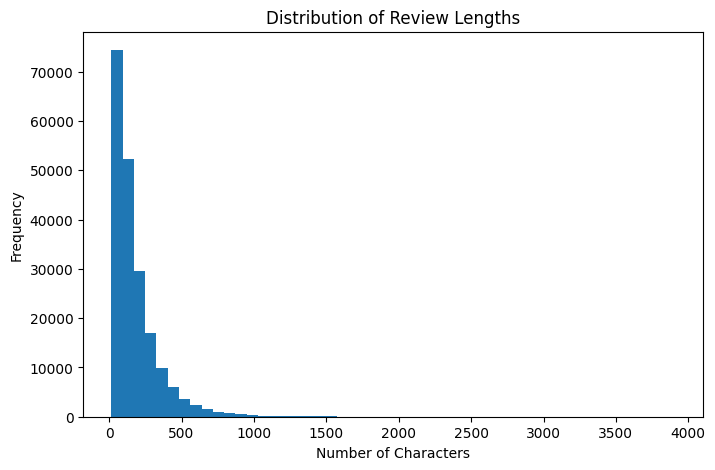

In [12]:
train_df["review_length"].plot(
    kind="hist",
    bins=50,
    figsize=(8, 5)
)

plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.show()

We will add a new column named 'sentiment':

In [13]:
def create_sentiment_label(stars):
    if stars <= 2:
        return "negative"
    elif stars == 3:
        return "neutral"
    else:
        return "positive"


train_df["sentiment"] = train_df["stars"].apply(create_sentiment_label)

train_df[["stars", "sentiment"]].head(10)

,stars,sentiment
0,1,negative
1,1,negative
2,1,negative
3,1,negative
4,1,negative
5,1,negative
6,1,negative
7,1,negative
8,1,negative
9,1,negative


In [14]:
train_df["sentiment"].value_counts()

sentiment
negative    80000
positive    80000
neutral     40000
Name: count, dtype: int64

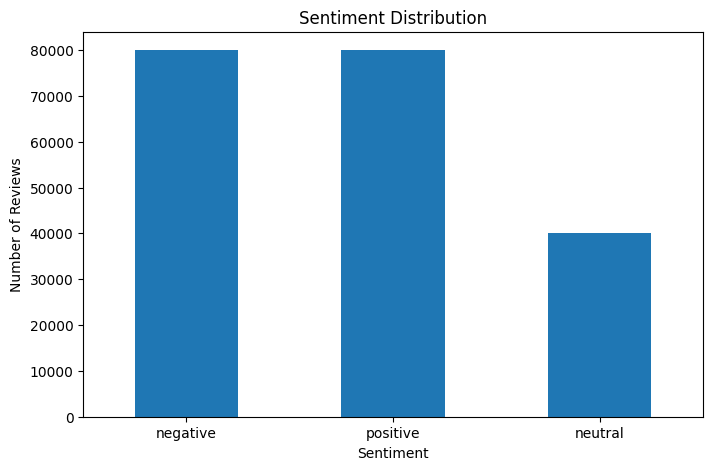

In [15]:
train_df["sentiment"].value_counts().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

In [16]:
def prepare_split(split):
    df = split.to_pandas()

    df["sentiment"] = df["stars"].apply(create_sentiment_label)

    return df


train_df = prepare_split(dataset["train"])
val_df = prepare_split(dataset["validation"])
test_df = prepare_split(dataset["test"])

print("Train:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Train: (200000, 9)
Validation: (5000, 9)
Test: (5000, 9)


In [17]:
print("Train:")
print(train_df["sentiment"].value_counts())

print("\nValidation:")
print(val_df["sentiment"].value_counts())

print("\nTest:")
print(test_df["sentiment"].value_counts())

Train:
sentiment
negative    80000
positive    80000
neutral     40000
Name: count, dtype: int64

Validation:
sentiment
negative    2000
positive    2000
neutral     1000
Name: count, dtype: int64

Test:
sentiment
negative    2000
positive    2000
neutral     1000
Name: count, dtype: int64


In [18]:
print("Missing values:")
print(train_df[["review_body", "sentiment"]].isnull().sum())

print("\nDuplicate reviews:")
print(train_df["review_body"].duplicated().sum())

Missing values:
review_body    0
sentiment      0
dtype: int64

Duplicate reviews:
574


In [19]:
duplicate_reviews = train_df[
    train_df["review_body"].duplicated(keep=False)
].sort_values("review_body")

duplicate_reviews[
    ["review_body", "stars", "sentiment"]
].head(20)

,review_body,stars,sentiment
47986,A lot smaller than I thought,2,negative
101471,A lot smaller than I thought,3,neutral
103981,A lot smaller than I thought,3,neutral
61826,A lot smaller than expected.,2,negative
108397,A lot smaller than expected.,3,neutral
167255,Absolutely beautiful!,5,positive
171911,Absolutely beautiful!,5,positive
161704,Arrived on time in good condition.,5,positive
161751,Arrived on time in good condition.,5,positive
169700,"As describe, would buy again",5,positive


In [20]:
train_df_clean = train_df.drop_duplicates(
    subset=["review_body", "sentiment"]
).copy()

print("Original:", len(train_df))
print("After removing exact duplicates:", len(train_df_clean))
print("Removed:", len(train_df) - len(train_df_clean))

Original: 200000
After removing exact duplicates: 199499
Removed: 501


In [21]:
train_df_clean[
    ["review_body", "stars", "sentiment"]
].head()


,review_body,stars,sentiment
0,Arrived broken. Manufacturer defect. Two of th...,1,negative
1,the cabinet dot were all detached from backing...,1,negative
2,I received my first order of this product and ...,1,negative
3,This product is a piece of shit. Do not buy. D...,1,negative
4,went through 3 in one day doesn't fit correct ...,1,negative


In [22]:
val_df_clean = val_df.drop_duplicates(
    subset=["review_body", "sentiment"]
).copy()

test_df_clean = test_df.drop_duplicates(
    subset=["review_body", "sentiment"]
).copy()

print("Validation:")
print("Original:", len(val_df))
print("After cleaning:", len(val_df_clean))
print("Removed:", len(val_df) - len(val_df_clean))

print("\nTest:")
print("Original:", len(test_df))
print("After cleaning:", len(test_df_clean))
print("Removed:", len(test_df) - len(test_df_clean))

Validation:
Original: 5000
After cleaning: 4999
Removed: 1

Test:
Original: 5000
After cleaning: 5000
Removed: 0


Text Normalization :

In [24]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [25]:
train_df_clean["text"] = train_df_clean["review_body"].apply(clean_text)
val_df_clean["text"] = val_df_clean["review_body"].apply(clean_text)
test_df_clean["text"] = test_df_clean["review_body"].apply(clean_text)

print(train_df_clean[["review_body", "text"]].head())

                                         review_body  \
0  Arrived broken. Manufacturer defect. Two of th...   
1  the cabinet dot were all detached from backing...   
2  I received my first order of this product and ...   
3  This product is a piece of shit. Do not buy. D...   
4  went through 3 in one day doesn't fit correct ...   

                                                text  
0  arrived broken. manufacturer defect. two of th...  
1  the cabinet dot were all detached from backing...  
2  i received my first order of this product and ...  
3  this product is a piece of shit. do not buy. d...  
4  went through 3 in one day doesn't fit correct ...  
